In [1]:
library('tidymodels')
library('palmerpenguins')
library('vip')

theme_set(theme_gray(base_size = 16))

── Attaching packages ──────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ─────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Use tidymodels_prefer() to resolve common conflicts.

Attaching package: ‘palmerpenguins’

The following object 

In [2]:
penguins2 = penguins |>
    drop_na()

penguins2 |> head()

  species island    bill_length_mm bill_depth_mm flipper_length_mm body_mass_g
1 Adelie  Torgersen 39.1           18.7          181               3750       
2 Adelie  Torgersen 39.5           17.4          186               3800       
3 Adelie  Torgersen 40.3           18.0          195               3250       
4 Adelie  Torgersen 36.7           19.3          193               3450       
5 Adelie  Torgersen 39.3           20.6          190               3650       
6 Adelie  Torgersen 38.9           17.8          181               3625       
  sex    year
1 male   2007
2 female 2007
3 female 2007
4 female 2007
5 male   2007
6 female 2007

## Use random forests to model `bill_length_mm`

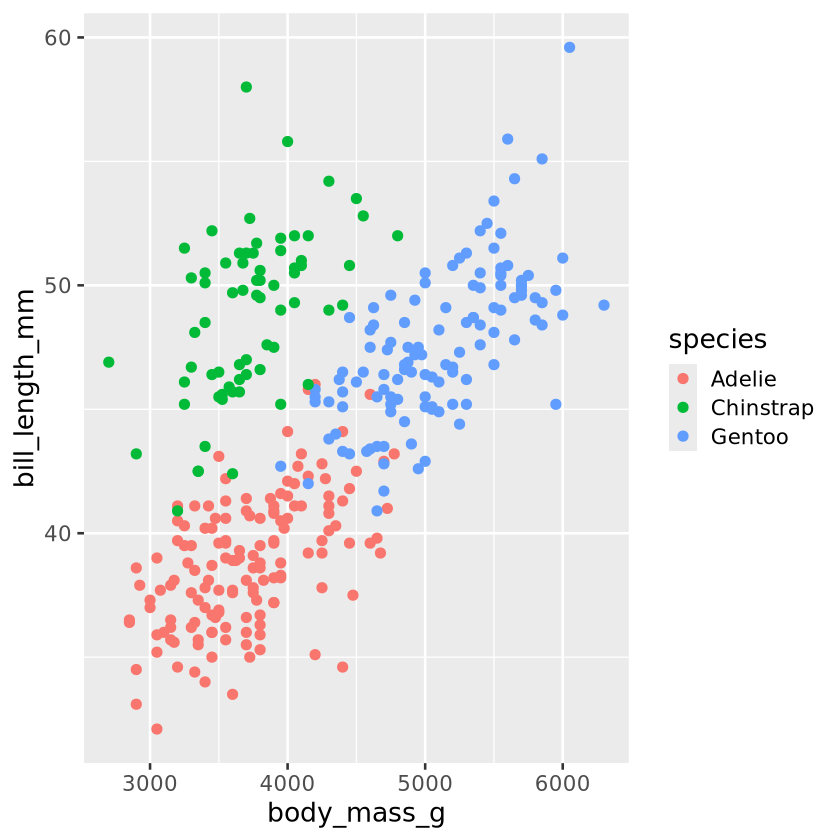

In [6]:
ggplot(penguins2, aes(y = bill_length_mm, x = body_mass_g, color = species)) +
    geom_point()

In [5]:
penguins2 |> names()

[1] "species"           "island"            "bill_length_mm"   
[4] "bill_depth_mm"     "flipper_length_mm" "body_mass_g"      
[7] "sex"               "year"             

In [10]:
mod = rand_forest() |> set_mode('regression')

mod

Random Forest Model Specification (regression)

Computational engine: ranger 


In [3]:
# mod = rand_forest() |> 
#     set_engine('ranger', importance = 'impurity') |>
#     set_mode('regression')

In [12]:
mod_fit = mod |> fit(bill_length_mm ~ ., data = penguins2)

mod_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, num.threads = 1,      verbose = FALSE, seed = sample.int(10^5, 1)) 

Type:                             Regression 
Number of trees:                  500 
Sample size:                      333 
Number of independent variables:  7 
Mtry:                             2 
Target node size:                 5 
Variable importance mode:         none 
Splitrule:                        variance 
OOB prediction error (MSE):       5.263555 
R squared (OOB):                  0.8239987 

In [49]:
predict(mod_fit, new_data = penguins2) |>
    bind_cols(penguins2) |>
    head()
# ggplot(aes(y = bill_length_mm, x = body_mass_g, color = species)) + 
#     geom_point() +
#     geom_line(aes(y = .pred))

  .pred    species island    bill_length_mm bill_depth_mm flipper_length_mm
1 39.21018 Adelie  Torgersen 39.1           18.7          181              
2 38.20778 Adelie  Torgersen 39.5           17.4          186              
3 38.92040 Adelie  Torgersen 40.3           18.0          195              
4 37.64226 Adelie  Torgersen 36.7           19.3          193              
5 39.09619 Adelie  Torgersen 39.3           20.6          190              
6 38.73802 Adelie  Torgersen 38.9           17.8          181              
  body_mass_g sex    year
1 3750        male   2007
2 3800        female 2007
3 3250        female 2007
4 3450        female 2007
5 3650        male   2007
6 3625        female 2007

In [ ]:
rec = recipe(bill_length_mm ~ ., data = penguins2) |>
    step_rm(year) |>
    step_dummy(sex, island, species) |>
    prep(retain = TRUE)

rec |> juice() |> head()

In [ ]:
wf = workflow() |> 
  add_recipe(rec) |> 
  add_model(mod)

wf_fit = wf |> fit(data = penguins2)

wf_fit

In [ ]:
outcomes = augment(wf_fit |> extract_fit_parsnip(), 
                   new_data = rec |> juice())

outcomes |> head()

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 5)

ggplot(outcomes) +
    geom_point(aes(x = bill_depth_mm, y = bill_length_mm)) + 
    geom_point(aes(x = bill_depth_mm, y = .pred), color = 'steelblue', size = 3,
               alpha = 0.5) +
    geom_segment(aes(x = bill_depth_mm, xend = bill_depth_mm, y = .pred, yend = bill_length_mm), 
                 color = 'firebrick',
                 alpha = 0.25)

## Visualize feature importance

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4)

wf_fit |> 
  extract_fit_parsnip() |> 
  vip()

## Use a single decision tree to model `bill_length_mm`

In [19]:
tree_mod = decision_tree() |> set_mode('regression')

tree_mod

Decision Tree Model Specification (regression)

Computational engine: rpart 


In [20]:
tree_fit = tree_mod |> fit(bill_length_mm ~ ., data = penguins2)

tree_fit

parsnip model object

n= 333 

node), split, n, deviance, yval
      * denotes terminal node

 1) root 333 9928.9030 43.99279  
   2) species=Adelie 146 1027.9660 38.82397  
     4) sex=female 73  296.3784 37.25753 *
     5) sex=male 73  373.3433 40.39041 *
   3) species=Chinstrap,Gentoo 187 1954.8800 48.02834  
     6) sex=female 92  580.5943 45.93696 *
     7) sex=male 95  582.1962 50.05368  
      14) bill_depth_mm< 16.45 53  248.0483 49.09434 *
      15) bill_depth_mm>=16.45 42  223.8164 51.26429 *

In [ ]:
predict(tree_fit, new_data = penguins2) |>
    bind_cols(penguins2) |>
ggplot(aes(y = bill_length_mm, x = body_mass_g, color = species)) + 
    geom_point() +
    geom_line(aes(y = .pred))

Loading required package: rpart

Attaching package: ‘rpart’

The following object is masked from ‘package:dials’:

    prune

Warning message:
“Cannot retrieve the data used to build the model (so cannot determine roundint and is.binary for the variables).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE.”


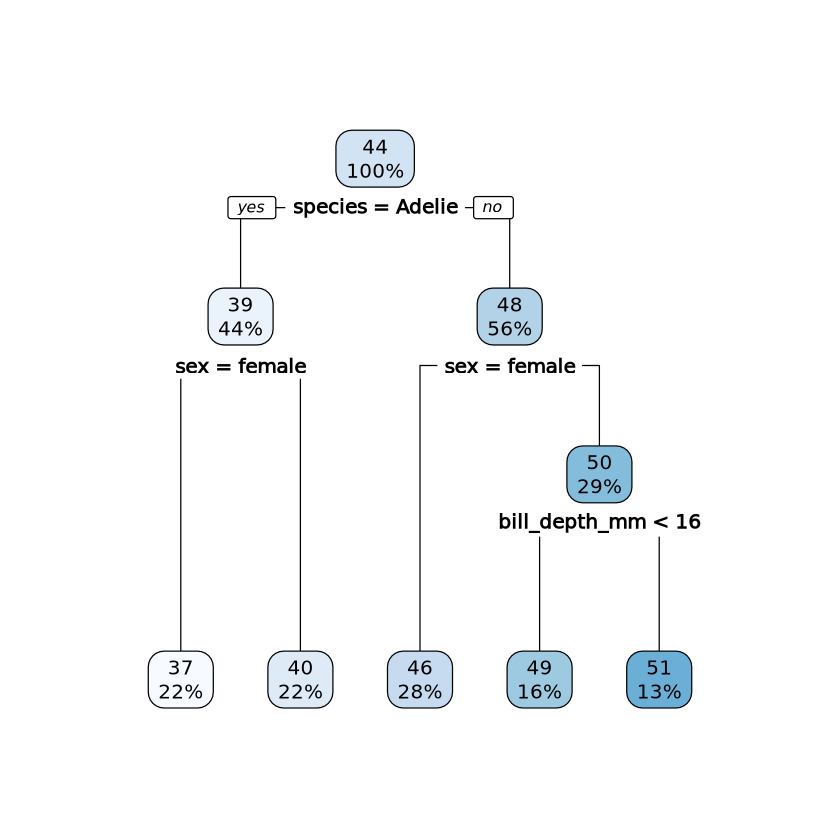

In [22]:
library('rpart.plot')

tree_fit |> 
    extract_fit_engine() |> 
    rpart.plot()

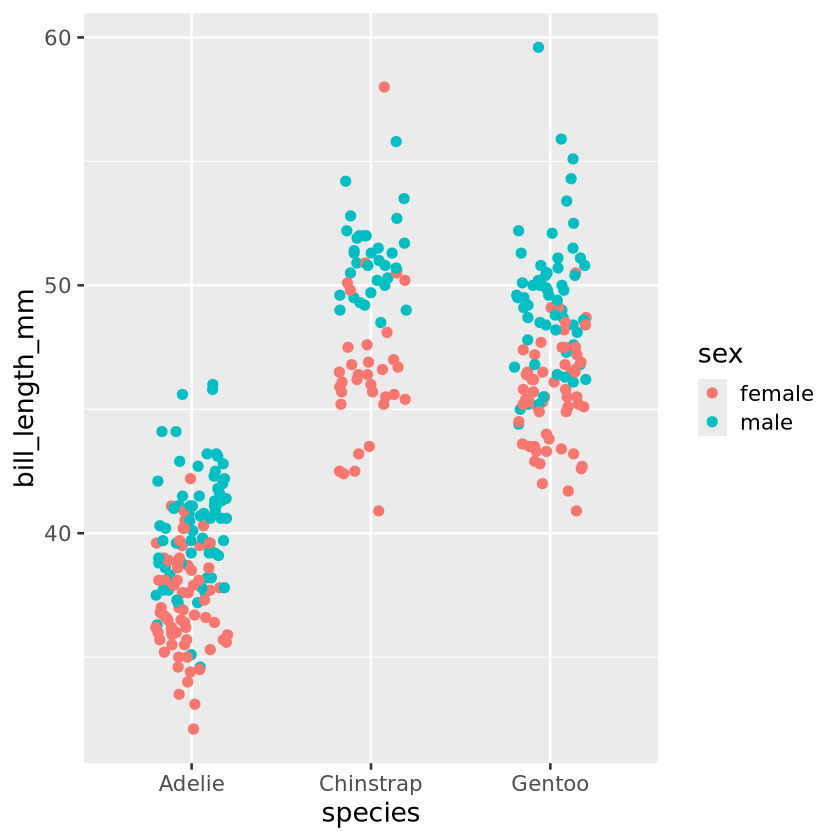

In [24]:
ggplot(penguins2, aes(x = species, y = bill_length_mm, color = sex)) + 
    geom_point(position = position_jitter(width = 0.2, height = 0))

"high bias"

not good a generalizing

RF solves theses issues

We can't get more data, maybe we can understand variability due to sampling by the bootstrap


In [33]:
nrow(penguins2)

[1] 333

In [48]:
# bootstrap

penguins2 |>
    mutate(rn = row_number()) |>
    sample_n(size = nrow(penguins2), replace = TRUE) |>
    count(rn) |>
    arrange(desc(n)) |>
    head()

  rn  n
1  36 4
2  96 4
3 119 4
4 141 4
5 157 4
6 192 4